# 평론가와 관객은 왜 다르게 볼까?
### 로튼토마토 영화 데이터로 본 평론가 평점과 관객 평점의 차이 분석

**연구 질문**
1. 평론가와 관객의 평가는 얼마나, 어떻게 다른가?
2. 어떤 영화에서 두 평가가 크게 갈리는가? (장르, 제작사, 인기도)
3. 평론가와 관객의 평가 차이는 시대에 따라 어떻게 변해 왔는가?

**데이터:** Kaggle "Rotten Tomatoes movies and critic reviews dataset" 중 `rotten_tomatoes_movies.csv` (2020년 10월 31일 기준 수집, 영화 17,712편)

**분석 절차:** 데이터 점검 → 전처리(결측치·중복치·파생변수·이상치) → 탐색적 분석 → 그룹별 평가 차이 비교 → k-평균 군집 → 분류 모델(로지스틱 회귀·의사결정트리·랜덤포레스트) 비교 → 시계열 분석 → 결론

## 0. 환경 설정
코랩에서는 아래 셀에서 한글 폰트(나눔고딕) 설치. 코랩이 아닌 환경에서는 설치를 건너뛰고 컴퓨터에 있는 한글 폰트 사용.

In [37]:
# ── 한글 폰트 설치 (코랩에서만 실행) ──
import sys
if 'google.colab' in sys.modules:
    !apt-get -qq -y install fonts-nanum > /dev/null

In [38]:
# ── 라이브러리 불러오기 ──
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (silhouette_score, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)
warnings.filterwarnings('ignore')

# ── 한글 폰트 설정 ──
# 코랩에서 설치한 나눔고딕이 있으면 등록, 없으면 컴퓨터에 있는 한글 폰트 중 하나 사용
NANUM_PATH = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(NANUM_PATH):
    fm.fontManager.addfont(NANUM_PATH)
installed = {f.name for f in fm.fontManager.ttflist}
chosen_font = next((n for n in ['NanumGothic', 'Malgun Gothic', 'AppleGothic'] if n in installed), 'sans-serif')
sns.set_theme(style='whitegrid', rc={'font.family': chosen_font, 'axes.unicode_minus': False})  # 마이너스 기호 깨짐 방지
print('사용 폰트:', chosen_font)

# ── 경로와 공통 설정 ──
DATA_PATH = 'rotten_tomatoes_movies.csv'   # 데이터 파일
FIG_DIR = 'figures'                        # 그래프 저장 폴더
os.makedirs(FIG_DIR, exist_ok=True)
RANDOM_STATE = 42                          # 무작위 결과 고정
CRITIC, AUDIENCE = '#C44E52', '#4C72B0'    # 그래프 색: 평론가 빨강, 관객 파랑

def save(fig, name):
    """그래프를 figures 폴더에 png로 저장"""
    fig.tight_layout()
    fig.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

사용 폰트: NanumGothic


## 1. 데이터 수집

| 컬럼 | 의미 |
|---|---|
| `tomatometer_rating` | 평론가 점수: 긍정(Fresh) 평가를 한 평론가의 비율(%) |
| `audience_rating` | 관객 점수: 별점 3.5점(5점 만점) 이상을 준 관객의 비율(%) |
| `tomatometer_count` / `audience_count` | 평론가 리뷰 수 / 관객 평가 수 |
| `genres`, `content_rating` | 장르(복수 가능), 관람 등급 |
| `original_release_date`, `production_company` | 개봉일, 제작·배급사 |

두 점수 모두 "긍정 평가 비율(0~100%)"이므로 같은 척도로 비교 가능.

In [39]:
# ── CSV 파일 읽기 ──
raw = pd.read_csv(DATA_PATH)
print('원본 크기 (행, 열):', raw.shape)
raw.head(3)

원본 크기 (행, 열): (17712, 22)


,rotten_tomatoes_link,movie_title,movie_info,critics_consensus,content_rating,genres,directors,authors,actors,original_release_date,...,production_company,tomatometer_status,tomatometer_rating,tomatometer_count,audience_status,audience_rating,audience_count,tomatometer_top_critics_count,tomatometer_fresh_critics_count,tomatometer_rotten_critics_count
0,m/0814255,Percy Jackson & the Olympians: The Lightning T...,"Always trouble-prone, the life of teenager Per...",Though it may seem like just another Harry Pot...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,"Craig Titley, Chris Columbus, Rick Riordan","Logan Lerman, Brandon T. Jackson, Alexandra Da...",2010-02-12,...,20th Century Fox,Rotten,49.0,149.0,Spilled,53.0,254421.0,43,73,76
1,m/0878835,Please Give,Kate (Catherine Keener) and her husband Alex (...,Nicole Holofcener's newest might seem slight i...,R,Comedy,Nicole Holofcener,Nicole Holofcener,"Catherine Keener, Amanda Peet, Oliver Platt, R...",2010-04-30,...,Sony Pictures Classics,Certified-Fresh,87.0,142.0,Upright,64.0,11574.0,44,123,19
2,m/10,10,"A successful, middle-aged Hollywood songwriter...",Blake Edwards' bawdy comedy may not score a pe...,R,"Comedy, Romance",Blake Edwards,Blake Edwards,"Dudley Moore, Bo Derek, Julie Andrews, Robert ...",1979-10-05,...,Waner Bros.,Fresh,67.0,24.0,Spilled,53.0,14684.0,2,16,8


### 1-1. 데이터 기본 점검

In [40]:
# ── 자료형과 결측치가 아닌 값의 개수 ──
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17712 entries, 0 to 17711
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   rotten_tomatoes_link              17712 non-null  object 
 1   movie_title                       17712 non-null  object 
 2   movie_info                        17391 non-null  object 
 3   critics_consensus                 9134 non-null   object 
 4   content_rating                    17712 non-null  object 
 5   genres                            17693 non-null  object 
 6   directors                         17518 non-null  object 
 7   authors                           16170 non-null  object 
 8   actors                            17360 non-null  object 
 9   original_release_date             16546 non-null  object 
 10  streaming_release_date            17328 non-null  object 
 11  runtime                           17398 non-null  float64
 12  prod

In [41]:
# ── 분석에 쓸 컬럼의 결측치 개수와 비율 ──
USE_COLS = ['tomatometer_rating', 'audience_rating', 'tomatometer_count', 'audience_count',
            'genres', 'content_rating', 'original_release_date', 'production_company']
missing = pd.DataFrame({'결측치 수': raw[USE_COLS].isnull().sum(),
                        '결측치 비율(%)': (raw[USE_COLS].isnull().mean() * 100).round(2)})
missing

,결측치 수,결측치 비율(%)
tomatometer_rating,44,0.25
audience_rating,296,1.67
tomatometer_count,44,0.25
audience_count,297,1.68
genres,19,0.11
content_rating,0,0.00
original_release_date,1166,6.58
production_company,499,2.82


In [42]:
# ── 수치형 컬럼 기술통계 ──
raw.describe().round(1)

,runtime,tomatometer_rating,tomatometer_count,audience_rating,audience_count,tomatometer_top_critics_count,tomatometer_fresh_critics_count,tomatometer_rotten_critics_count
count,17398.0,17668.0,17668.0,17416.0,17415.0,17712.0,17712.0,17712.0
mean,102.2,60.9,57.1,60.6,143940.1,14.6,36.4,20.7
std,18.7,28.4,68.4,20.5,1763577.4,15.1,52.6,30.2
min,5.0,0.0,5.0,0.0,5.0,0.0,0.0,0.0
25%,90.0,38.0,12.0,45.0,707.5,3.0,6.0,3.0
50%,99.0,67.0,28.0,63.0,4277.0,8.0,16.0,8.0
75%,111.0,86.0,75.0,78.0,24988.0,23.0,44.0,24.0
max,266.0,100.0,574.0,100.0,35797635.0,69.0,497.0,303.0


In [43]:
# ── 문자형(object) 컬럼 기술통계: 값의 종류 수(unique), 가장 많은 값(top)과 그 빈도(freq) ──
raw[['content_rating', 'genres', 'production_company', 'tomatometer_status', 'audience_status']].describe(include='object')

,content_rating,genres,production_company,tomatometer_status,audience_status
count,17712,17693,17213,17668,17264
unique,6,1106,3046,3,2
top,R,Drama,Paramount Pictures,Rotten,Upright
freq,6377,1887,517,7565,9390


**점검 결과**
- 평론가 점수 결측 44건, 관객 점수 결측 296건
- 개봉일은 문자형이며 1,166건이 결측
- `audience_count`는 최솟값 5, 최댓값 약 3,580만으로 분포가 크게 치우침
- `content_rating`의 `NR`은 결측이 아니라 등급 미분류(Not Rated)를 뜻하는 값

## 2. 전처리
### 2-1. 결측치 처리 및 분석 대상 선정

| 컬럼 | 처리 | 근거 |
|---|---|---|
| 평론가 점수, 관객 점수 | 삭제 | 비교 대상 변수이므로 대체값을 넣으면 평가 차이가 왜곡됨 |
| 개봉일 | 날짜형 변환 후 연도 추출(`Int64`), 결측 삭제 | 시계열 분석에 필요 |
| 장르 | 빈 문자열로 대체 | 19건, 장르 변수를 모두 0으로 처리 |
| 제작사 | '기타'로 대체 | 제작사 유형 분류에서 정보 없음으로 처리 |

리뷰 수가 적은 영화는 점수가 불안정하므로 평론가 리뷰 20개 이상, 관객 평가 500개 이상인 영화만 분석.

In [44]:
# ── 분석 대상 필터링 ──
MIN_CRITICS, MIN_AUDIENCE = 20, 500
df = raw.copy()   # 원본(raw)은 그대로 두고 복사본에서 작업

# 개봉일 → 날짜형 → 연도 (변환 실패 값은 결측 처리)
df['year'] = pd.to_datetime(df['original_release_date'], errors='coerce').dt.year.astype('Int64')

steps = [('원본', len(df))]
df = df.dropna(subset=['tomatometer_rating', 'audience_rating'])
steps.append(('두 점수 모두 있음', len(df)))
df = df[df['tomatometer_count'] >= MIN_CRITICS]
steps.append((f'평론가 리뷰 {MIN_CRITICS}개 이상', len(df)))
df = df[df['audience_count'] >= MIN_AUDIENCE]
steps.append((f'관객 평가 {MIN_AUDIENCE}개 이상', len(df)))
df = df.dropna(subset=['year'])
steps.append(('개봉 연도 있음', len(df)))

# 남은 결측치 대체
df['genres'] = df['genres'].fillna('')
df['production_company'] = df['production_company'].fillna('기타')
df = df.reset_index(drop=True)
pd.DataFrame(steps, columns=['단계', '영화 수'])

,단계,영화 수
0,원본,17712
1,두 점수 모두 있음,17407
2,평론가 리뷰 20개 이상,10787
3,관객 평가 500개 이상,9766
4,개봉 연도 있음,9615


이 기준으로 표본이 어느 정도 알려진 영화 위주로 구성됨. 따라서 이후 결론은 리뷰가 일정 수 이상 쌓인 영화에 한정해 해석.

### 2-2. 중복치 확인

In [45]:
# ── 완전히 같은 행, 같은 영화 주소 중복 ──
print('완전히 같은 행:', df.duplicated().sum(), '건')
print('영화 주소 중복:', df.duplicated(subset='rotten_tomatoes_link').sum(), '건')

# ── 제목과 개봉 연도가 같은 영화 (keep=False: 중복된 행 모두 표시) ──
same_title = df[df.duplicated(subset=['movie_title', 'year'], keep=False)]
same_title[['rotten_tomatoes_link', 'movie_title', 'year', 'directors']].sort_values('movie_title')

완전히 같은 행: 0 건
영화 주소 중복: 0 건


,rotten_tomatoes_link,movie_title,year,directors


완전히 같은 행이나 영화 주소가 중복된 행은 없음. 제목·연도가 같은 영화는 감독이 다른 별개 작품이므로 유지.

### 2-3. 파생변수 생성
- `gap` = 관객 점수 − 평론가 점수 (양수: 관객이 더 후함, 음수: 평론가가 더 후함)
- 장르 원-핫 인코딩 (한 영화에 여러 장르가 붙어 있으므로 장르별 0/1 변수 생성)
- 제작사 유형: 메이저 스튜디오 / 예술영화 배급사 / 넷플릭스 / 기타
  - 메이저 스튜디오의 예술영화 자회사(Searchlight, Vantage, Classics 등)를 먼저 예술영화 배급사로 분류
  - 다른 회사명 안에 키워드가 섞여 잘못 걸리지 않도록 단어 단위로 검사하고, 분류 결과를 직접 확인

In [46]:
# ── 핵심 변수: 평가 차이 ──
df['gap'] = df['audience_rating'] - df['tomatometer_rating']

# ── 장르 원-핫 인코딩 ──
GENRE_KO = {'Drama': '드라마', 'Comedy': '코미디', 'Action & Adventure': '액션·모험',
            'Mystery & Suspense': '미스터리·스릴러', 'Art House & International': '예술·해외영화',
            'Documentary': '다큐멘터리', 'Horror': '공포', 'Romance': '로맨스',
            'Science Fiction & Fantasy': 'SF·판타지', 'Classics': '고전', 'Kids & Family': '가족',
            'Musical & Performing Arts': '뮤지컬', 'Animation': '애니메이션', 'Western': '서부극',
            'Special Interest': '특별 관심사', 'Faith & Spirituality': '종교'}
genre_lists = df['genres'].str.split(', ')                       # "Drama, Comedy" → ['Drama', 'Comedy']
for eng, ko in GENRE_KO.items():
    df['g_' + ko] = genre_lists.apply(lambda g: int(eng in g))  # 해당 장르가 있으면 1, 없으면 0
GENRE_COLS = ['g_' + ko for ko in GENRE_KO.values()]

# ── 제작사 유형 ──
# 메이저 스튜디오의 예술영화 자회사(Fox Searchlight, Paramount Vantage, Warner Independent, ○○ Classics 등)가
# 메이저로 잘못 분류되지 않도록 예술영화 배급사를 먼저 확인
MAJOR = ['Paramount', 'Warner', 'Universal', '20th Century', 'Twentieth Century', 'Fox', 'Columbia',
         'Sony Pictures Releasing', 'Disney', 'Lionsgate', 'MGM', 'DreamWorks', 'New Line']
ARTHOUSE = ['IFC', 'Magnolia', 'Classics', 'A24', 'Focus Features', 'Searchlight', 'Vantage', 'Warner Independent',
            'Universal Focus', 'Oscilloscope', 'Kino', 'Criterion', 'Strand', 'Music Box', 'Zeitgeist', 'Neon']

def has_word(name, keywords):
    """회사명에 키워드가 단어 단위로 들어 있는지 확인 (예: 'Neon'이 'Geneon'에 걸리지 않도록 \\b 경계 사용)"""
    return any(re.search(r'\b' + re.escape(k.lower()) + r'\b', name) for k in keywords)

def studio_type(name):
    """제작사 이름 → 제작사 유형"""
    name = name.lower()
    if 'netflix' in name:
        return '넷플릭스'
    if has_word(name, ARTHOUSE):
        return '예술영화 배급사'
    if has_word(name, MAJOR):
        return '메이저 스튜디오'
    return '기타'

df['studio'] = df['production_company'].apply(studio_type)
df['studio'].value_counts()

,count
studio,
기타,4362
메이저 스튜디오,3644
예술영화 배급사,1546
넷플릭스,63


In [47]:
# ── 분류 검증: 유형별로 어떤 제작사가 들어갔는지 상위 8개씩 확인 ──
# 키워드가 엉뚱한 회사 이름에 걸리지 않았는지 직접 점검
for t in ['메이저 스튜디오', '예술영화 배급사', '넷플릭스']:
    top = df.loc[df['studio'] == t, 'production_company'].value_counts().head(8)
    print(f'[{t}]', ', '.join(f'{n}({c})' for n, c in top.items()))

[메이저 스튜디오] Warner Bros. Pictures(446), Universal Pictures(415), 20th Century Fox(373), Paramount Pictures(371), Columbia Pictures(177), Warner Home Video(175), MGM(150), New Line Cinema(128)
[예술영화 배급사] IFC Films(274), Sony Pictures Classics(247), Magnolia Pictures(198), Focus Features(126), Fox Searchlight Pictures(72), Criterion Collection(61), Music Box Films(57), Fox Searchlight(51)
[넷플릭스] Netflix(62), Netflix Originals(1)


### 2-4. 이상치 확인 (IQR, Z-점수)

In [48]:
# ── IQR과 Z-점수로 이상치 개수 세기 ──
def outlier_count(s):
    """IQR 기준(1.5배)과 |Z|>3 기준 이상치 개수"""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    z_out = (((s - s.mean()) / s.std()).abs() > 3).sum()
    return pd.Series({'IQR 이상치': iqr_out, '|Z|>3 이상치': z_out})

OUTLIER_COLS = ['tomatometer_rating', 'audience_rating', 'gap', 'tomatometer_count', 'audience_count']
pd.DataFrame({c: outlier_count(df[c]) for c in OUTLIER_COLS}).T

,IQR 이상치,|Z|>3 이상치
tomatometer_rating,0,0
audience_rating,0,0
gap,139,34
tomatometer_count,291,153
audience_count,1507,50


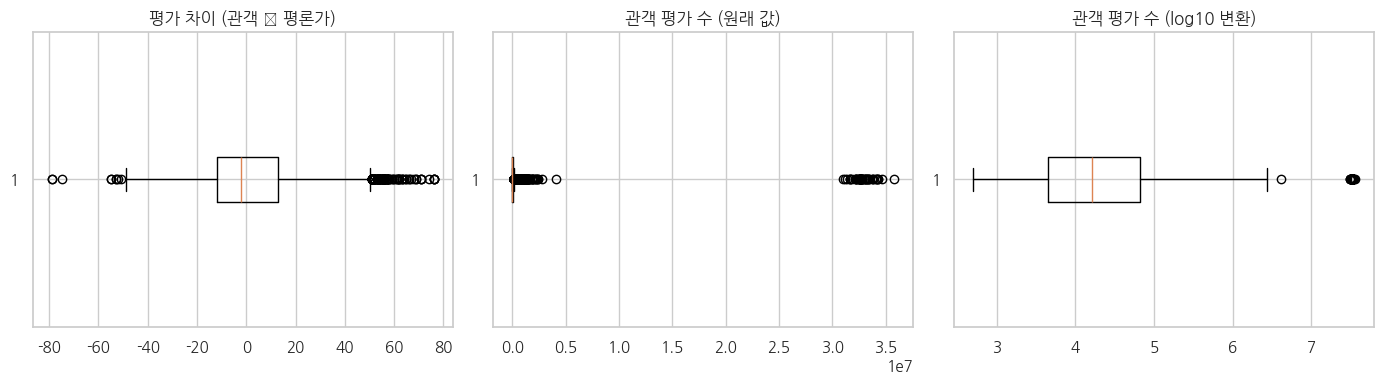

In [49]:
# ── 박스플롯: 평가 차이 / 관객 평가 수(원래 값, 로그 변환 후) ──
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].boxplot(df['gap'], vert=False); axes[0].set_title('평가 차이 (관객 − 평론가)')
axes[1].boxplot(df['audience_count'], vert=False); axes[1].set_title('관객 평가 수 (원래 값)')
axes[2].boxplot(np.log10(df['audience_count']), vert=False); axes[2].set_title('관객 평가 수 (log10 변환)')
save(fig, '00_outliers'); plt.show()

**이상치 처리**

| 변수 | 판단 | 처리 |
|---|---|---|
| 평가 차이 | 입력 오류가 아닌, 평가가 극단적으로 갈린 실제 사례 | 유지, 3-4에서 사례로 분석 |
| 관객 평가 수 | 분포가 극단적으로 치우쳐 소수의 대작이 분석을 지배 | log10 변환 |
| 평론가·관객 점수 | 0~100 범위의 정상 값 | 그대로 사용 |

In [50]:
# ── 로그 변환한 인기도 변수 ──
df['log_audience_count'] = np.log10(df['audience_count'])
df['log_critic_count'] = np.log10(df['tomatometer_count'])
print('최종 분석 대상:', len(df), '편')

최종 분석 대상: 9615 편


## 3. 탐색적 분석
### 3-1. 평론가 점수와 관객 점수의 분포

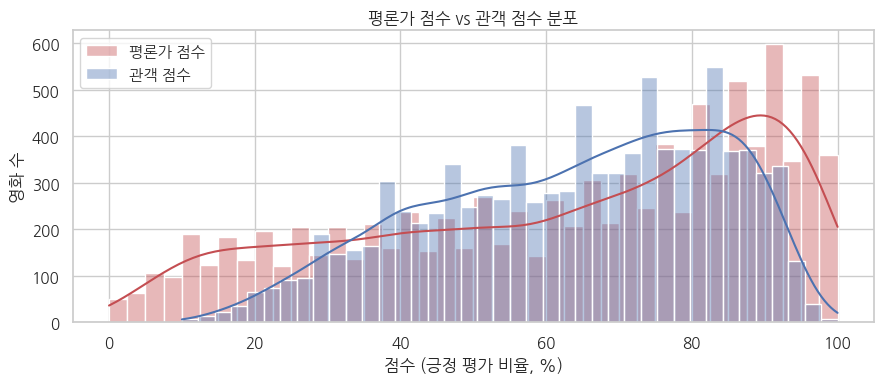

,mean,std,min,50%,max
평론가 점수,62.4,27.5,0.0,68.0,100.0
관객 점수,63.6,19.6,10.0,66.0,100.0
평가 차이(관객−평론가),1.2,19.1,-79.0,-2.0,76.0


In [51]:
# ── 히스토그램 + KDE(분포를 부드러운 곡선으로 표시) ──
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df['tomatometer_rating'], bins=40, kde=True, color=CRITIC, alpha=0.4, label='평론가 점수', ax=ax)
sns.histplot(df['audience_rating'], bins=40, kde=True, color=AUDIENCE, alpha=0.4, label='관객 점수', ax=ax)
ax.set_xlabel('점수 (긍정 평가 비율, %)'); ax.set_ylabel('영화 수'); ax.legend()
ax.set_title('평론가 점수 vs 관객 점수 분포')
save(fig, '01_score_distribution'); plt.show()

summary = df[['tomatometer_rating', 'audience_rating', 'gap']].describe().T[['mean', 'std', 'min', '50%', 'max']].round(1)
summary.index = ['평론가 점수', '관객 점수', '평가 차이(관객−평론가)']
summary

평론가 점수의 표준편차(27.5)가 관객 점수(19.6)보다 큼. 평론가가 관객보다 호불호를 더 극단적으로 나누는 경향.

### 3-2. 평론가 점수와 관객 점수의 관계

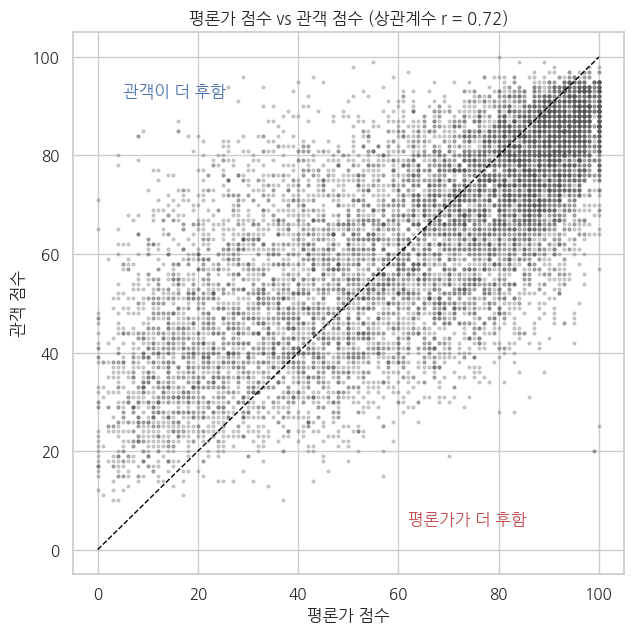

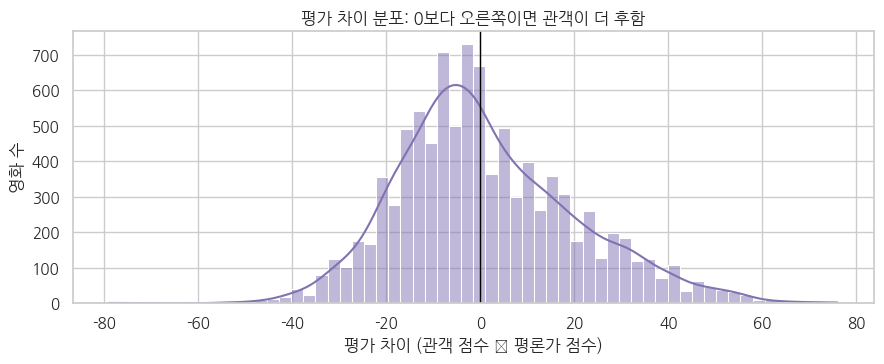

평가 차이가 20점 이상 나는 영화 비율: 28.7%


In [52]:
# ── 산점도 + 대각선(두 점수가 같은 선) ──
r = df['tomatometer_rating'].corr(df['audience_rating'])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(df['tomatometer_rating'], df['audience_rating'], s=4, alpha=0.25, color='#555555')
ax.plot([0, 100], [0, 100], ls='--', color='black', lw=1)
ax.text(5, 92, '관객이 더 후함', color=AUDIENCE, fontsize=12)
ax.text(62, 5, '평론가가 더 후함', color=CRITIC, fontsize=12)
ax.set_xlabel('평론가 점수'); ax.set_ylabel('관객 점수')
ax.set_title(f'평론가 점수 vs 관객 점수 (상관계수 r = {r:.2f})')
save(fig, '02_scatter'); plt.show()

# ── 평가 차이 분포 ──
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(df['gap'], bins=60, kde=True, color='#8172B2', ax=ax)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('평가 차이 (관객 점수 − 평론가 점수)'); ax.set_ylabel('영화 수')
ax.set_title('평가 차이 분포: 0보다 오른쪽이면 관객이 더 후함')
save(fig, '03_gap_distribution'); plt.show()
print(f"평가 차이가 20점 이상 나는 영화 비율: {(df['gap'].abs() >= 20).mean():.1%}")

### 3-3. 수치형 변수 간 상관관계

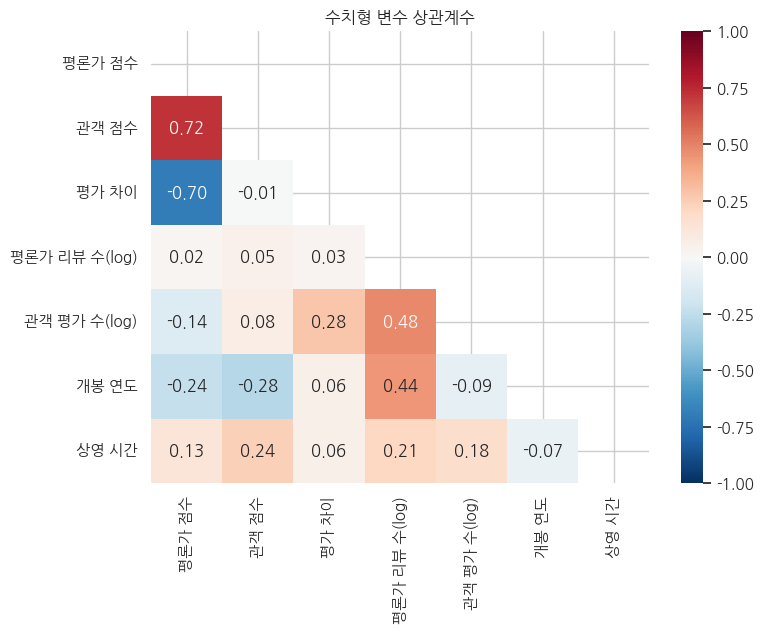

In [53]:
# ── 상관계수 히트맵 (위쪽 삼각형 가리기) ──
num_cols = {'tomatometer_rating': '평론가 점수', 'audience_rating': '관객 점수', 'gap': '평가 차이',
            'log_critic_count': '평론가 리뷰 수(log)', 'log_audience_count': '관객 평가 수(log)',
            'year': '개봉 연도', 'runtime': '상영 시간'}
corr = df[list(num_cols)].astype(float).corr().rename(index=num_cols, columns=num_cols)
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('수치형 변수 상관계수')
save(fig, '04_corr_heatmap'); plt.show()

- 평가 차이는 두 점수로 계산한 값이므로 평론가 점수와의 강한 음의 상관(−0.70)은 구조적인 결과임
- 주목할 부분은 관객 평가 수(인기도)와 평가 차이의 양의 상관(0.28) → 인기 있는 영화일수록 관객이 더 후하게 평가하는 경향

### 3-4. 평가가 크게 갈린 영화 사례

In [54]:
# ── 관객만 좋아한 영화 TOP 10 / 평론가만 좋아한 영화 TOP 10 ──
cols = {'movie_title': '제목', 'year': '개봉', 'tomatometer_rating': '평론가', 'audience_rating': '관객', 'gap': '차이'}
print('▶ 관객만 좋아한 영화 (관객 − 평론가가 가장 큰 영화)')
print(df.nlargest(10, 'gap')[list(cols)].rename(columns=cols).to_string(index=False))
print('\n▶ 평론가만 좋아한 영화 (평론가 − 관객이 가장 큰 영화)')
print(df.nsmallest(10, 'gap')[list(cols)].rename(columns=cols).to_string(index=False))

▶ 관객만 좋아한 영화 (관객 − 평론가가 가장 큰 영화)
                                                           제목   개봉  평론가   관객   차이
                       America: Imagine the World Without Her 2014  8.0 84.0 76.0
Hillary's America: The Secret History of the Democratic Party 2016  4.0 80.0 76.0
                                                     Out Cold 2001  8.0 84.0 76.0
                                                    Stonewall 2015  9.0 85.0 76.0
                                                   Modigliani 2004  4.0 78.0 74.0
                                                        Grind 2003  8.0 79.0 71.0
                                   Diary of a Mad Black Woman 2005 16.0 87.0 71.0
                                       A Low Down Dirty Shame 1994  0.0 71.0 71.0
                                            Facing the Giants 2006 16.0 85.0 69.0
                                                Grandma's Boy 2006 16.0 85.0 69.0

▶ 평론가만 좋아한 영화 (평론가 − 관객이 가장 큰 영화)
                              

## 4. 그룹별 평가 차이 비교
그룹별 평균 평가 차이와 95% 신뢰구간 비교. 신뢰구간이 0을 포함하지 않으면 해당 그룹의 평가 차이가 우연이라고 보기 어렵다고 판단.

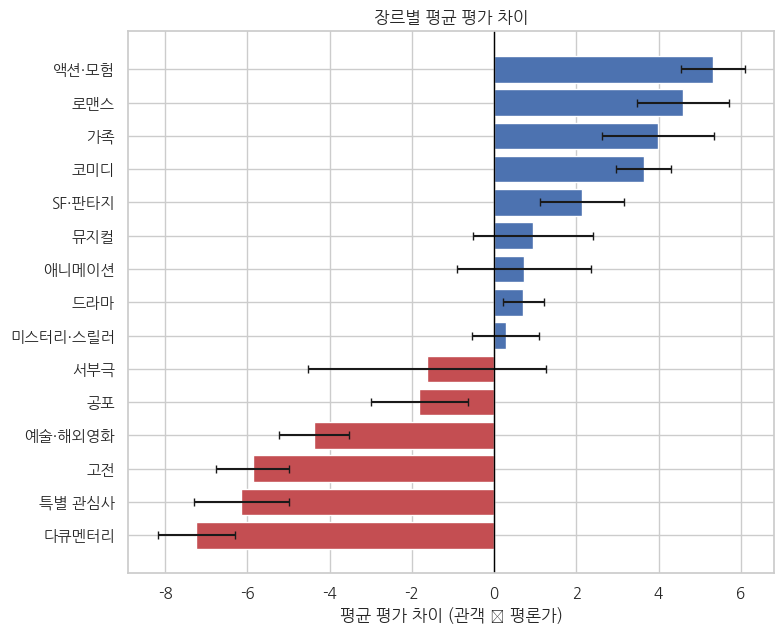

,평균차이,영화수,표준편차,오차
genre_ko,,,,
다큐멘터리,-7.2,803,13.6,0.9
특별 관심사,-6.1,585,14.3,1.2
고전,-5.9,625,11.4,0.9
예술·해외영화,-4.4,1304,15.7,0.9
공포,-1.8,973,18.9,1.2
서부극,-1.6,121,16.2,2.9
미스터리·스릴러,0.3,2035,18.7,0.8
드라마,0.7,5459,18.9,0.5
애니메이션,0.7,381,16.2,1.6


In [55]:
# ── 그룹별 평균 차이와 95% 신뢰구간 집계 함수 ──
def gap_table(data, by):
    """data를 by 컬럼으로 묶어 평가 차이의 평균, 영화 수, 95% 신뢰구간 오차를 계산"""
    t = data.groupby(by)['gap'].agg(평균차이='mean', 영화수='size', 표준편차='std')
    t['오차'] = 1.96 * t['표준편차'] / np.sqrt(t['영화수'])          # 1.96 × 표준오차
    return t.sort_values('평균차이')

def gap_barh(ax, t, title):
    """집계표를 가로 막대로 그림 (파랑: 관객이 더 후함, 빨강: 평론가가 더 후함)"""
    colors = np.where(t['평균차이'] > 0, AUDIENCE, CRITIC)
    ax.barh(t.index, t['평균차이'], xerr=t['오차'], color=colors, capsize=3)
    ax.axvline(0, color='black', lw=1)
    ax.set_xlabel('평균 평가 차이 (관객 − 평론가)'); ax.set_title(title)

# ── 4-1. 장르별 ──
# 한 영화에 장르가 여러 개이므로 explode로 "영화 × 장르" 한 줄씩 펼친 뒤 집계
genre_long = df[['gap']].assign(genre=genre_lists).explode('genre')
genre_long['genre_ko'] = genre_long['genre'].map(GENRE_KO)          # 영어 → 한글
genre_long = genre_long.dropna(subset=['genre_ko'])                  # 분석 대상이 아닌 장르 제외
genre_gap = gap_table(genre_long, 'genre_ko').query('영화수 >= 50')  # 50편 미만 장르는 제외

fig, ax = plt.subplots(figsize=(8, 6.5))
gap_barh(ax, genre_gap, '장르별 평균 평가 차이')
save(fig, '05_gap_by_genre'); plt.show()
genre_gap.round(1)

- 관객이 더 후한 장르: 액션·모험(+5.3), 로맨스(+4.6), 가족(+4.0), 코미디(+3.6)
- 평론가가 더 후한 장르: 다큐멘터리(−7.2), 특별 관심사(−6.1), 고전(−5.9), 예술·해외영화(−4.4)
- "공포영화는 평론가에게 박하다"는 통념과 달리 공포 장르는 평론가가 소폭 더 후함(−1.8)

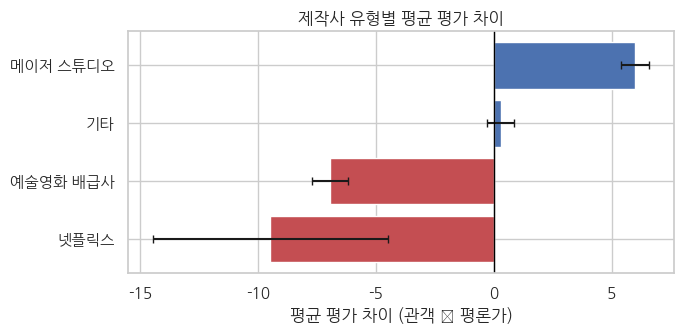

,평균차이,영화수,표준편차,오차
studio,,,,
넷플릭스,-9.5,63,20.2,5.0
예술영화 배급사,-7.0,1546,15.7,0.8
기타,0.3,4362,19.5,0.6
메이저 스튜디오,6.0,3644,18.5,0.6


In [56]:
# ── 4-2. 제작사 유형별 ──
studio_gap = gap_table(df, 'studio')
fig, ax = plt.subplots(figsize=(7, 3.5))
gap_barh(ax, studio_gap, '제작사 유형별 평균 평가 차이')
save(fig, '06_gap_by_studio'); plt.show()
studio_gap.round(1)

메이저 스튜디오 영화는 관객이, 예술영화 배급사 영화는 평론가가 더 후하게 평가. 넷플릭스는 63편으로 표본이 적어 신뢰구간이 넓으므로 해석에서 제외.

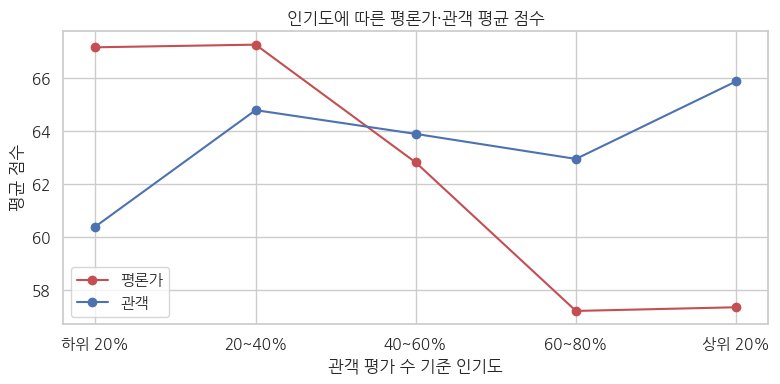

,tomatometer_rating,audience_rating
popularity,,
하위 20%,67.2,60.4
20~40%,67.3,64.8
40~60%,62.8,63.9
60~80%,57.2,62.9
상위 20%,57.3,65.9


In [57]:
# ── 4-3. 인기도별 ──
# 관객 평가 수를 5개 구간(각 20%)으로 나누고 구간별 평론가·관객 평균 점수 비교
df['popularity'] = pd.qcut(df['audience_count'], 5, labels=['하위 20%', '20~40%', '40~60%', '60~80%', '상위 20%'])
pop = df.groupby('popularity', observed=True)[['tomatometer_rating', 'audience_rating']].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pop.index.astype(str), pop['tomatometer_rating'], marker='o', color=CRITIC, label='평론가')
ax.plot(pop.index.astype(str), pop['audience_rating'], marker='o', color=AUDIENCE, label='관객')
ax.set_xlabel('관객 평가 수 기준 인기도'); ax.set_ylabel('평균 점수'); ax.legend()
ax.set_title('인기도에 따른 평론가·관객 평균 점수')
save(fig, '07_popularity'); plt.show()
pop.round(1)

### 4-4. 그룹 내 분포 비교

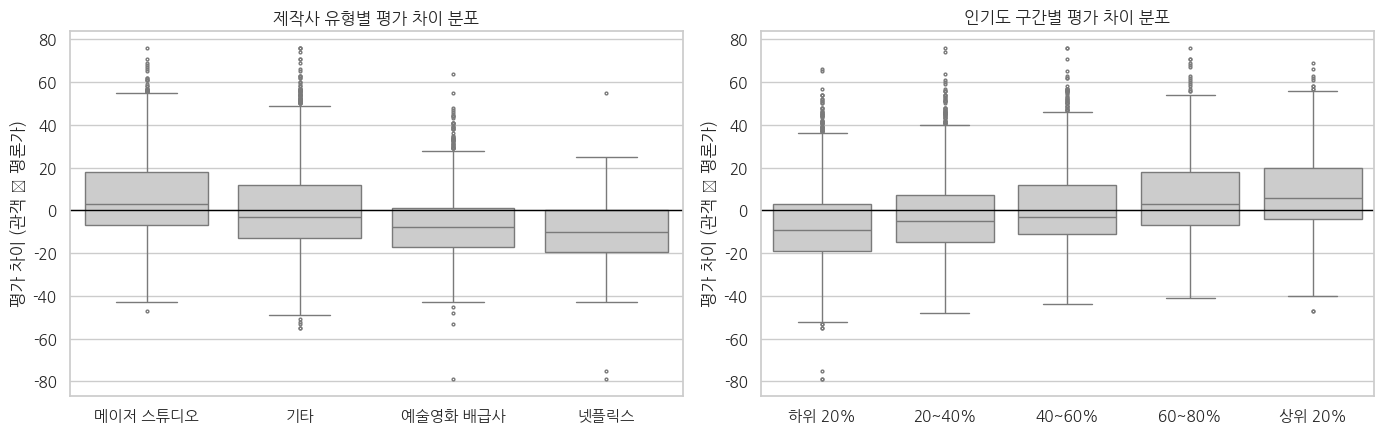

,0.25,0.50,0.75
studio,,,
기타,-13.0,-3.0,12.0
넷플릭스,-19.5,-10.0,0.0
메이저 스튜디오,-7.0,3.0,18.0
예술영화 배급사,-17.0,-8.0,1.0


In [58]:
# ── 제작사 유형별, 인기도 구간별 평가 차이 분포 ──
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x='studio', y='gap', order=['메이저 스튜디오', '기타', '예술영화 배급사', '넷플릭스'],
            color='#CCCCCC', fliersize=2, ax=axes[0])
sns.boxplot(data=df, x='popularity', y='gap', color='#CCCCCC', fliersize=2, ax=axes[1])
for ax, title in zip(axes, ['제작사 유형별', '인기도 구간별']):
    ax.axhline(0, color='black', lw=1)
    ax.set_xlabel(''); ax.set_ylabel('평가 차이 (관객 − 평론가)'); ax.set_title(f'{title} 평가 차이 분포')
save(fig, '08_boxplot'); plt.show()

# ── 제작사 유형별 사분위수 (가운데 50% 영화가 놓인 구간) ──
df.groupby('studio')['gap'].quantile([0.25, 0.5, 0.75]).unstack().round(1)

- 그룹 간 평균 차이는 뚜렷하지만 상자 범위가 크게 겹침 → "항상"이 아닌 "경향"으로 해석
- 인기도 구간이 올라갈수록 평가 차이의 중앙값이 꾸준히 증가

## 5. 군집 분석
### 5-1. 군집 변수 설정
두 점수를 그대로 쓰면 상관이 높아 영화가 점수 수준(좋음/보통/나쁨)으로만 나뉨. 평가 차이를 군집에 반영하기 위해 두 점수를 **평균 수준**과 **평가 차이**로 바꾼 뒤 표준화.

In [59]:
# ── 군집용 변수 만들기 → 표준화 ──
df['level'] = (df['tomatometer_rating'] + df['audience_rating']) / 2
X_cluster = StandardScaler().fit_transform(df[['level', 'gap']])     # 평균 수준·평가 차이 2개 변수

### 5-2. 군집 수(k) 결정
엘보우 방법과 실루엣 계수를 함께 확인. 해석 가능한 네 유형(명작·혹평작·관객 픽·평론가 픽)이 나오는 k=4 선택.

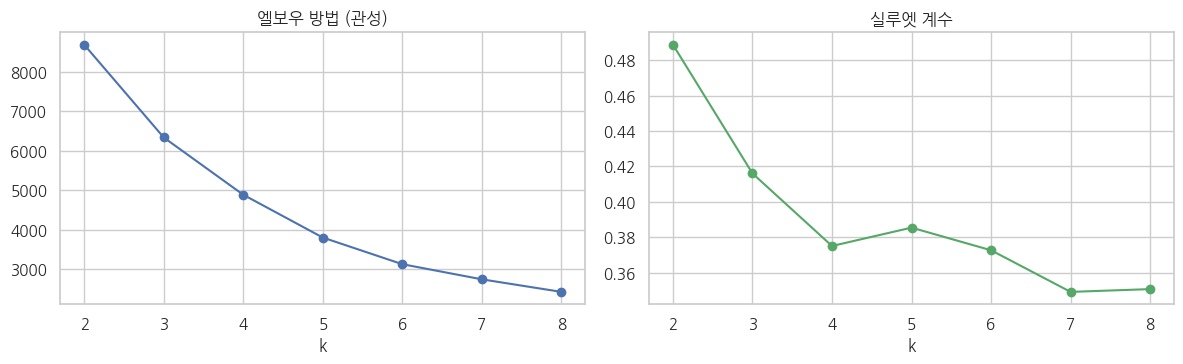

,k,관성,실루엣
0,2,8687.0,0.489
1,3,6336.0,0.416
2,4,4884.0,0.375
3,5,3800.0,0.385
4,6,3125.0,0.373
5,7,2741.0,0.349
6,8,2423.0,0.351


In [60]:
# ── k를 2~8까지 바꿔 가며 관성과 실루엣 계수 계산 ──
# 실루엣 계수는 계산량이 많아 5,000편을 무작위 추출해 계산
ks, inertias, silhouettes = range(2, 9), [], []
sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_cluster), 5000, replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster[sample_idx], km.labels_[sample_idx]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(list(ks), inertias, marker='o'); ax[0].set_title('엘보우 방법 (관성)'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), silhouettes, marker='o', color='#55A868'); ax[1].set_title('실루엣 계수'); ax[1].set_xlabel('k')
save(fig, '09_choose_k'); plt.show()
pd.DataFrame({'k': list(ks), '관성': np.round(inertias), '실루엣': np.round(silhouettes, 3)})

### 5-3. 군집 결과

In [61]:
# ── k=4로 최종 군집 ──
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
df['cluster'] = kmeans.labels_
# 표준화된 중심값은 해석이 어려우므로 군집별 원래 점수 평균 확인
centers = df.groupby('cluster')[['tomatometer_rating', 'audience_rating', 'level', 'gap']].mean()
centers.columns = ['평론가', '관객', '평균 수준', '평가 차이']

# ── 군집 이름 붙이기 ──
def name_cluster(c):
    """평가 차이 ±15 기준으로 관객 픽/평론가 픽, 그 외는 평균 수준 60 기준으로 명작/혹평작"""
    if c['평가 차이'] >= 15:
        return '관객 픽 (관객만 좋아함)'
    if c['평가 차이'] <= -15:
        return '평론가 픽 (평론가만 좋아함)'
    return '명작 (둘 다 좋아함)' if c['평균 수준'] >= 60 else '혹평작 (둘 다 싫어함)'
centers['유형'] = centers.apply(name_cluster, axis=1)
df['type'] = df['cluster'].map(centers['유형'])
centers['영화 수'] = df['cluster'].value_counts().sort_index()
centers.round(1)

,평론가,관객,평균 수준,평가 차이,유형,영화 수
cluster,,,,,,
0,84.0,81.1,82.5,-2.9,명작 (둘 다 좋아함),3963
1,33.5,40.6,37.0,7.1,혹평작 (둘 다 싫어함),2109
2,74.6,54.2,64.4,-20.4,평론가 픽 (평론가만 좋아함),2045
3,29.0,62.5,45.7,33.5,관객 픽 (관객만 좋아함),1498


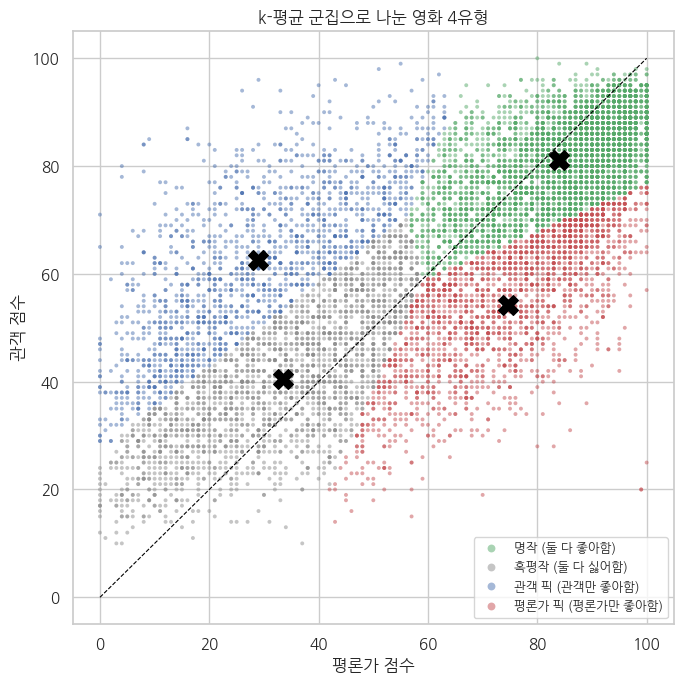

In [62]:
# ── 군집 결과 산점도 ──
TYPE_COLORS = {'명작 (둘 다 좋아함)': '#55A868', '혹평작 (둘 다 싫어함)': '#8C8C8C',
               '관객 픽 (관객만 좋아함)': AUDIENCE, '평론가 픽 (평론가만 좋아함)': CRITIC}
fig, ax = plt.subplots(figsize=(7, 7))
sns.scatterplot(data=df, x='tomatometer_rating', y='audience_rating', hue='type', palette=TYPE_COLORS,
                hue_order=list(TYPE_COLORS), s=8, alpha=0.5, linewidth=0, ax=ax)
ax.scatter(centers['평론가'], centers['관객'], marker='X', s=200, color='black')   # X: 유형별 평균 위치
ax.plot([0, 100], [0, 100], ls='--', color='black', lw=0.8)
ax.set_xlabel('평론가 점수'); ax.set_ylabel('관객 점수'); ax.set_title('k-평균 군집으로 나눈 영화 4유형')
ax.legend(title='', loc='lower right', fontsize=9, markerscale=2)
save(fig, '10_kmeans'); plt.show()

### 5-4. 유형별 특성

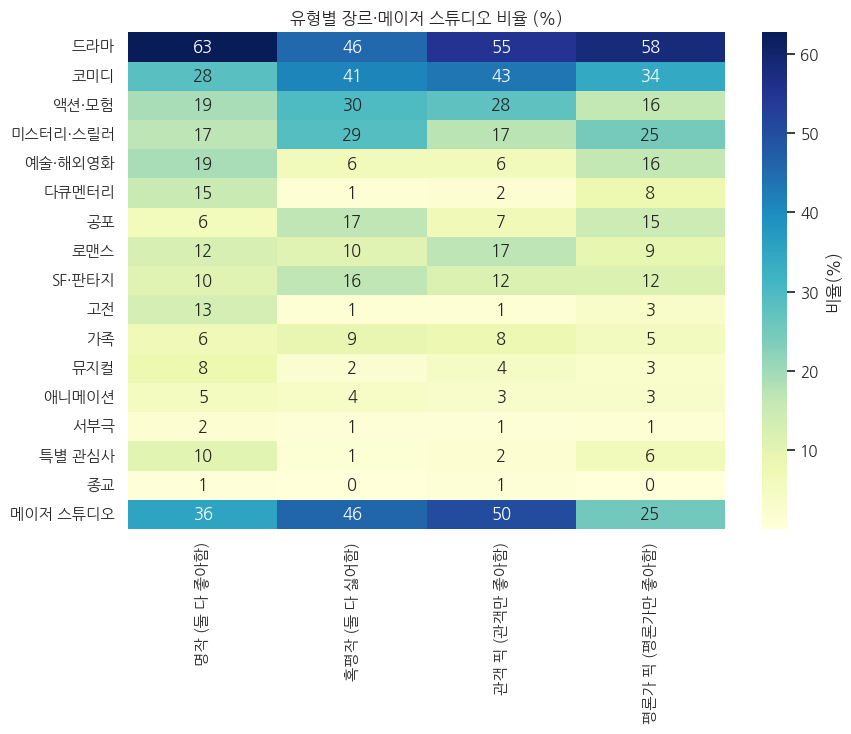

In [63]:
# ── 유형별 장르 비율 + 메이저 스튜디오 비율 (%) ──
type_order = list(TYPE_COLORS)
profile = df.groupby('type')[GENRE_COLS].mean().T * 100
profile.index = [c[2:] for c in profile.index]                     # 'g_' 접두어 제거
profile.loc['메이저 스튜디오'] = df.groupby('type')['studio'].apply(lambda s: (s == '메이저 스튜디오').mean() * 100)
profile = profile[type_order]

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(profile, annot=True, fmt='.0f', cmap='YlGnBu', ax=ax, cbar_kws={'label': '비율(%)'})
ax.set_title('유형별 장르·메이저 스튜디오 비율 (%)'); ax.set_xlabel(''); ax.set_ylabel('')
save(fig, '11_cluster_profile'); plt.show()

## 6. 분류 모델
평가 차이를 세 그룹(관객이 더 후함: +15 이상 / 비슷함 / 평론가가 더 후함: −15 이하)으로 나누고, 영화 정보로 그룹을 분류하는 모델을 만들어 평가 차이와 관련된 조건 탐색.

- 입력 변수: 장르, 관람 등급, 개봉 연도, 제작사 유형, 인기도(관객 평가 수, log)
- 평론가·관객 점수는 정답을 직접 계산할 수 있으므로 입력에서 제외
- 관객 평가 수는 점수와 같은 시점에 쌓이는 사후 지표이므로 인과관계가 아닌 상관관계로만 해석
- 그룹 크기가 달라 평가 지표로 세 그룹 재현율의 평균을 사용 (무작위 기준 0.333)

In [64]:
# ── 정답값 만들기 ──
GAP_CUT = 15
df['gap_class'] = np.select([df['gap'] >= GAP_CUT, df['gap'] <= -GAP_CUT], ['관객이 더 후함', '평론가가 더 후함'], '비슷함')
print(df['gap_class'].value_counts(), '\n')

# ── 입력 변수 만들기 (관람 등급·제작사 유형은 원-핫 인코딩) ──
X = pd.concat([
    df[GENRE_COLS + ['year', 'log_audience_count']],
    pd.get_dummies(df['content_rating'], prefix='등급'),
    pd.get_dummies(df['studio'], prefix='제작사'),
], axis=1).astype(float)                                             # Int64·bool → 실수형 통일
X = X.rename(columns={'year': '개봉연도', 'log_audience_count': '인기도(관객 평가 수)'})
X.columns = [re.sub(r'^g_', '장르_', c) for c in X.columns]

y = df['gap_class']
CLASS_NAMES = sorted(y.unique())                                     # 모델 내부 그룹 순서 (가나다순)
print('입력 변수 개수:', X.shape[1])

gap_class
비슷함          5559
관객이 더 후함     2167
평론가가 더 후함    1889
Name: count, dtype: int64 

입력 변수 개수: 28


### 6-1. 훈련/테스트 분리
훈련 80%, 테스트 20%로 층화 분리. 모델 선택과 튜닝은 훈련 데이터의 층화 5겹 교차검증으로만 수행.

In [65]:
# ── 훈련/테스트 분리 (그룹 비율 유지) + 5겹 교차검증 설정 ──
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('훈련:', X_train.shape, ' 테스트:', X_test.shape)

훈련: (7692, 28)  테스트: (1923, 28)


### 6-2. 의사결정트리
깊이별 교차검증 점수 비교. 깊이를 늘려도 성능 향상이 작아 규칙 해석이 가능한 깊이 3 선택.

In [66]:
# ── 깊이별 교차검증 점수 비교 (가지치기) ──
# class_weight='balanced': 적은 그룹에 더 큰 가중치를 줘서 그룹 크기 차이 보정
depth_scores = {}
for d in [2, 3, 4, 5, 6, 8, None]:
    dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE)
    depth_scores[str(d)] = cross_val_score(dt, X_train, y_train, cv=skf, scoring='recall_macro').mean()
pd.Series(depth_scores, name='재현율(교차검증)').rename_axis('max_depth').round(3).to_frame()

,재현율(교차검증)
max_depth,
2,0.482
3,0.509
4,0.522
5,0.525
6,0.527
8,0.532
None,0.532


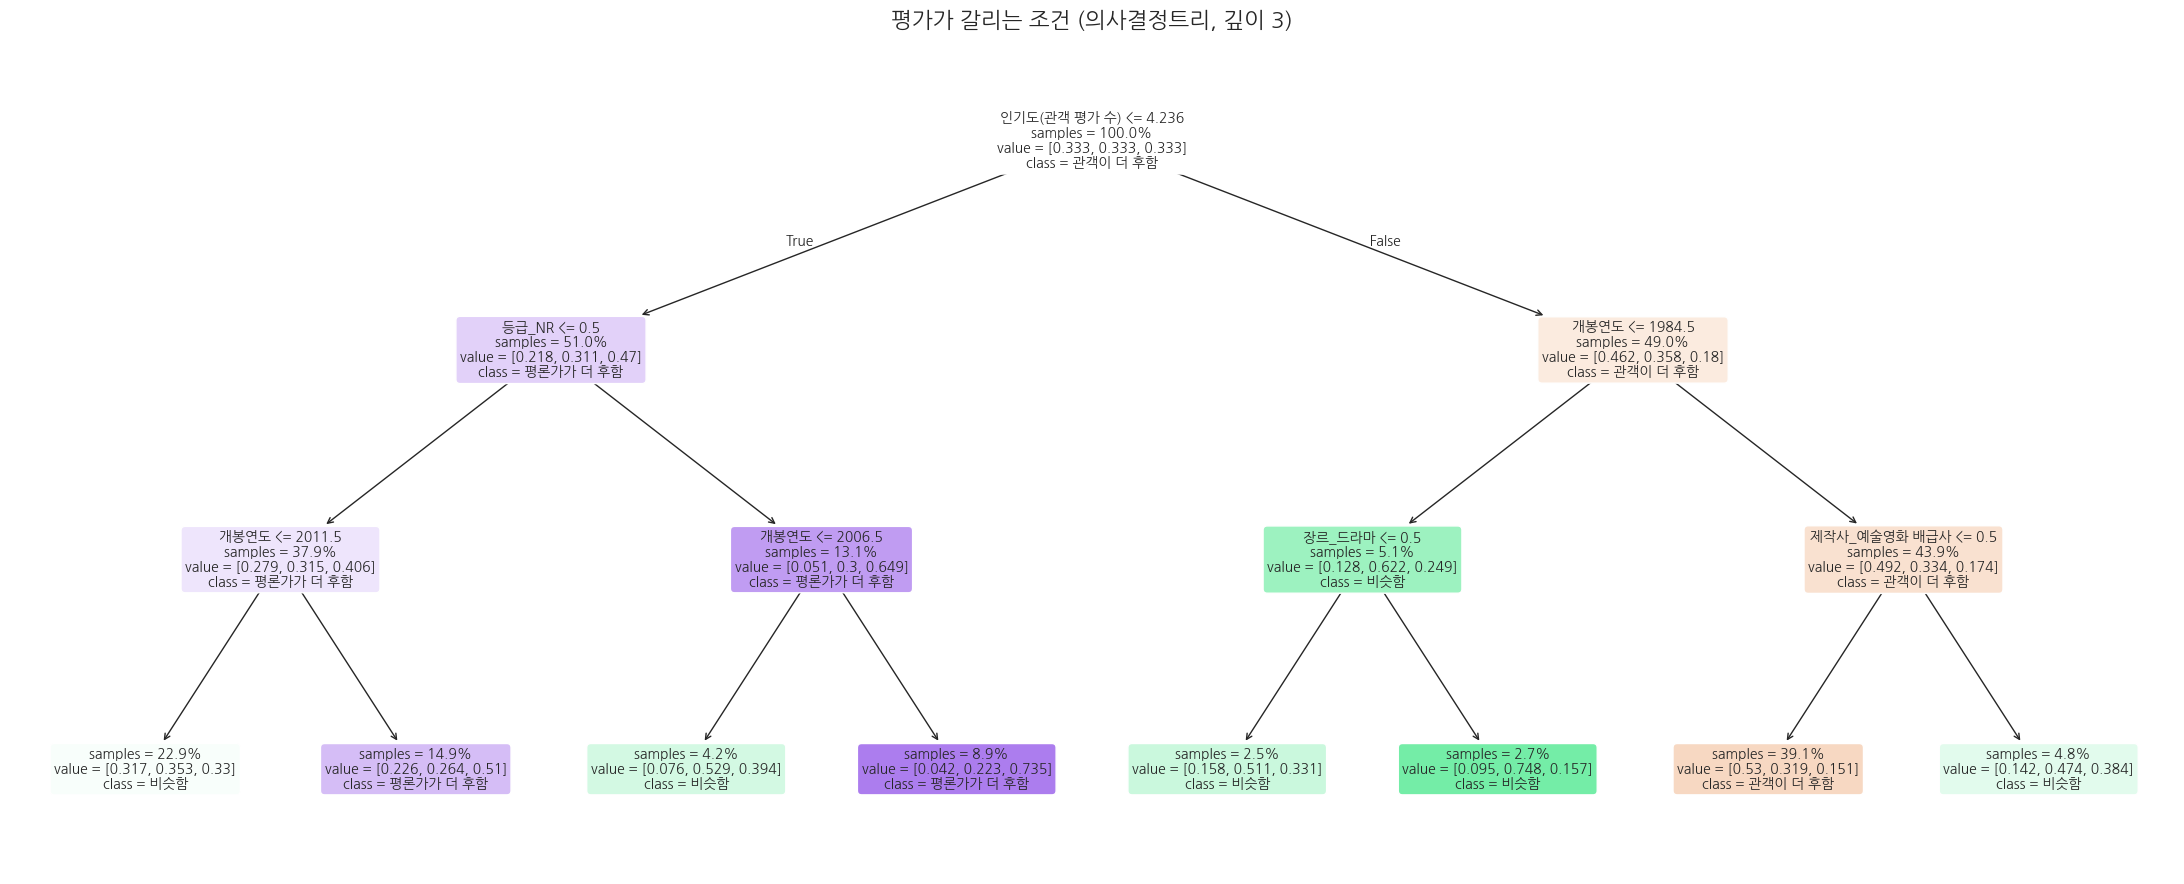

맨 위 질문: 인기도(관객 평가 수) <= 4.236 → 관객 평가 약 17,206개


In [67]:
# ── 깊이 3 트리를 훈련 데이터로 학습하고 그리기 ──
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(tree, feature_names=list(X.columns), class_names=CLASS_NAMES,
          filled=True, rounded=True, fontsize=10, impurity=False, proportion=True, ax=ax)
ax.set_title('평가가 갈리는 조건 (의사결정트리, 깊이 3)', fontsize=16)
save(fig, '12_decision_tree'); plt.show()

# 인기도는 로그값이므로 맨 위 기준값을 실제 관객 평가 수로 변환해 확인
root = X.columns[tree.tree_.feature[0]]
print(f"맨 위 질문: {root} <= {tree.tree_.threshold[0]:.3f}"
      + (f" → 관객 평가 약 {10**tree.tree_.threshold[0]:,.0f}개" if '인기도' in root else ''))

최상위 분기는 관객 평가 약 1만 7천 개 기준의 인기도.
- 인기도가 낮은 영화 중 최근 개봉작(2012년 이후, 등급 미분류 영화는 2007년 이후) → **평론가가 더 후함**
- 인기도가 높은 영화 중 1985년 이후 개봉, 예술영화 배급사 작품이 아닌 영화 → **관객이 더 후함**

### 6-3. 랜덤포레스트
변수 중요도를 확인할 수 있는 랜덤포레스트 사용. 훈련 데이터에서 그리드 서치로 하이퍼파라미터를 정한 뒤 테스트 데이터로 최종 평가.

In [68]:
# ── 그리드 서치 (훈련 데이터, 5겹 교차검증) ──
param_grid = {
    'n_estimators': [200, 400],           # 트리 개수
    'max_depth': [8, 12, None],           # 트리 최대 깊이 (None = 제한 없음)
    'min_samples_leaf': [5, 20],          # 잎(마지막 상자)에 있어야 할 최소 영화 수
}
# 병렬 처리는 GridSearchCV에서만 설정 (모델까지 n_jobs=-1이면 병렬이 겹침)
gs = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                  param_grid, cv=skf, scoring='recall_macro', n_jobs=-1)
gs.fit(X_train, y_train)
best_rf = gs.best_estimator_
print('최적 하이퍼파라미터:', gs.best_params_)
print(f'교차검증 재현율: {gs.best_score_:.3f}')

# ── 테스트 데이터로 최종 평가 (테스트 데이터는 여기서 처음 사용) ──
y_pred = best_rf.predict(X_test)
test_recall = recall_score(y_test, y_pred, average='macro')       # 세 그룹 재현율의 평균
print(f'테스트 재현율:  {test_recall:.3f}  (무작위로 찍으면 0.333)')

최적 하이퍼파라미터: {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 400}
교차검증 재현율: 0.560
테스트 재현율:  0.553  (무작위로 찍으면 0.333)


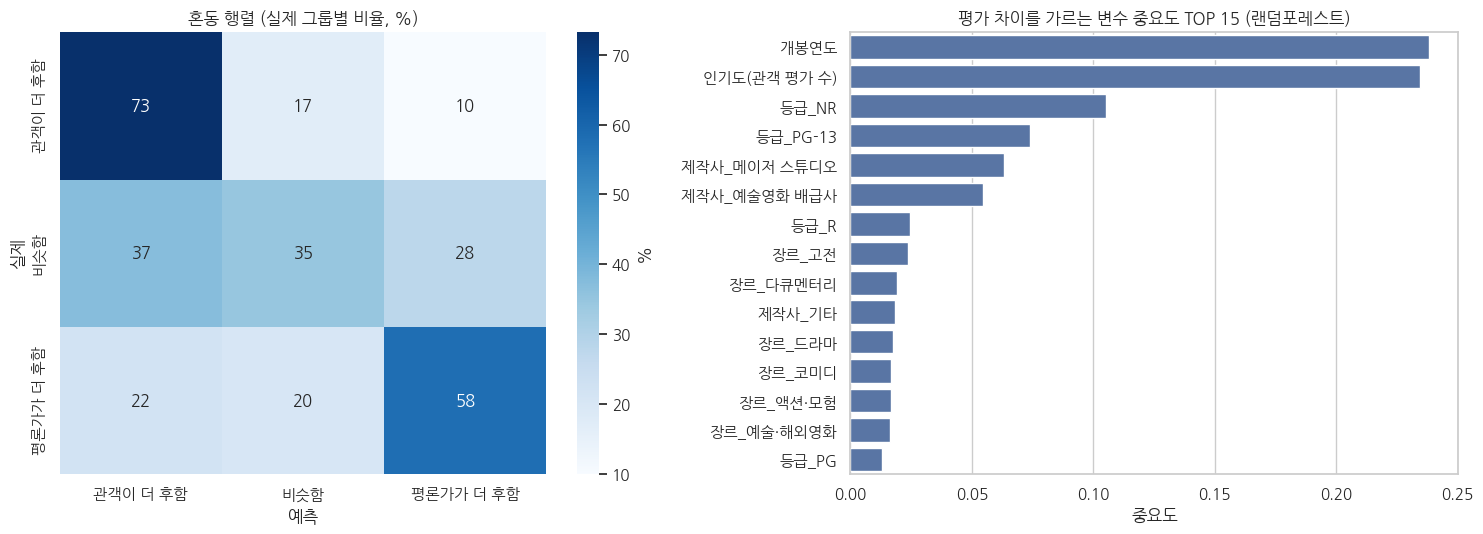

In [69]:
# ── 혼동 행렬: 실제 그룹(행) vs 예측 그룹(열) ──
cm = confusion_matrix(y_test, y_pred, labels=CLASS_NAMES, normalize='true') * 100   # 실제 그룹별 비율(%)
cm = pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '%'}, ax=axes[0])
axes[0].set_xlabel('예측'); axes[0].set_ylabel('실제'); axes[0].set_title('혼동 행렬 (실제 그룹별 비율, %)')

# ── 변수 중요도 상위 15개 ──
imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(x=imp.head(15).values, y=imp.head(15).index, color='#4C72B0', ax=axes[1])
axes[1].set_title('평가 차이를 가르는 변수 중요도 TOP 15 (랜덤포레스트)'); axes[1].set_xlabel('중요도'); axes[1].set_ylabel('')
save(fig, '13_rf_result'); plt.show()

- 교차검증과 테스트 성능이 비슷함 → 과적합 없이 일반화됨
- 다만 성능이 0.56 수준이므로 영화 정보만으로는 평가 차이를 충분히 설명하기 어려움. 연출·연기·마케팅 등 데이터에 없는 요인의 영향이 큰 것으로 보임

### 6-4. 모델별 성능 비교
로지스틱 회귀, 의사결정트리(깊이 3), 튜닝한 랜덤포레스트를 같은 훈련 데이터로 학습하고 같은 테스트 데이터에서 정확도·정밀도·재현율·F1(그룹별 값의 세 그룹 평균) 비교.

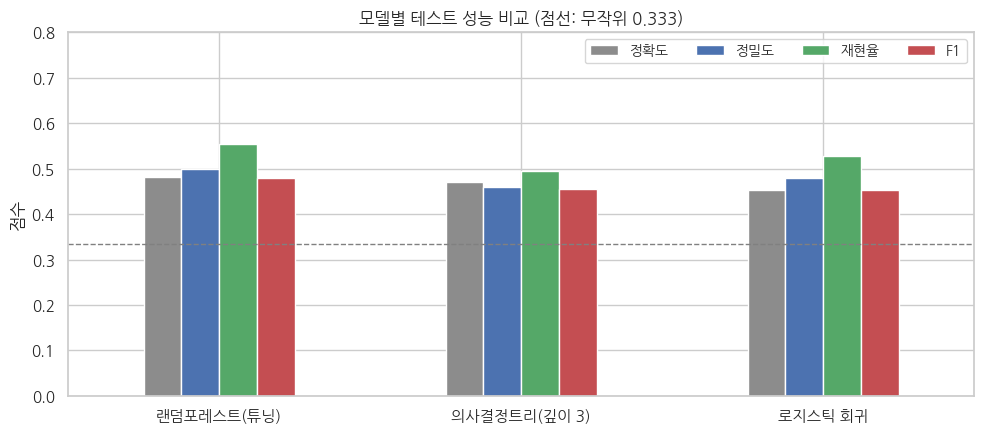

,정확도,정밀도,재현율,F1
모델,,,,
랜덤포레스트(튜닝),0.480,0.498,0.553,0.480
의사결정트리(깊이 3),0.470,0.461,0.495,0.455
로지스틱 회귀,0.453,0.478,0.528,0.453


In [70]:
# ── 비교할 모델 (랜덤포레스트는 6-3에서 튜닝한 모델 사용) ──
compare = {
    '로지스틱 회귀': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    '의사결정트리(깊이 3)': DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE),
}
for m in compare.values():
    m.fit(X_train, y_train)
compare['랜덤포레스트(튜닝)'] = best_rf

# ── 테스트 데이터로 지표 계산 ──
rows = []
for name, m in compare.items():
    p = m.predict(X_test)
    rows.append({'모델': name,
                 '정확도': accuracy_score(y_test, p),
                 '정밀도': precision_score(y_test, p, average='macro'),
                 '재현율': recall_score(y_test, p, average='macro'),
                 'F1': f1_score(y_test, p, average='macro')})
model_table = pd.DataFrame(rows).set_index('모델').sort_values('F1', ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
metric_colors = ['#8C8C8C', '#4C72B0', '#55A868', '#C44E52']   # 정확도·정밀도·재현율·F1 순서
model_table.plot(kind='bar', ax=ax, color=metric_colors, rot=0)
ax.axhline(1/3, ls='--', color='gray', lw=1)
ax.set_ylim(0, 0.8); ax.set_ylabel('점수'); ax.set_xlabel('')
ax.set_title('모델별 테스트 성능 비교 (점선: 무작위 0.333)'); ax.legend(loc='upper right', ncol=4, fontsize=10)
save(fig, '14_model_comparison'); plt.show()
model_table.round(3)

## 7. 시계열 분석
영화가 30편 이상인 연도만 사용하고 5년 이동평균(슬라이딩 윈도우)으로 추세 확인. 오래된 영화일수록 현재까지 평가받는 명작 위주로 남아 있을 가능성(생존자 편향)이 있어 과거 연도의 점수 수준은 해석에 주의 필요.

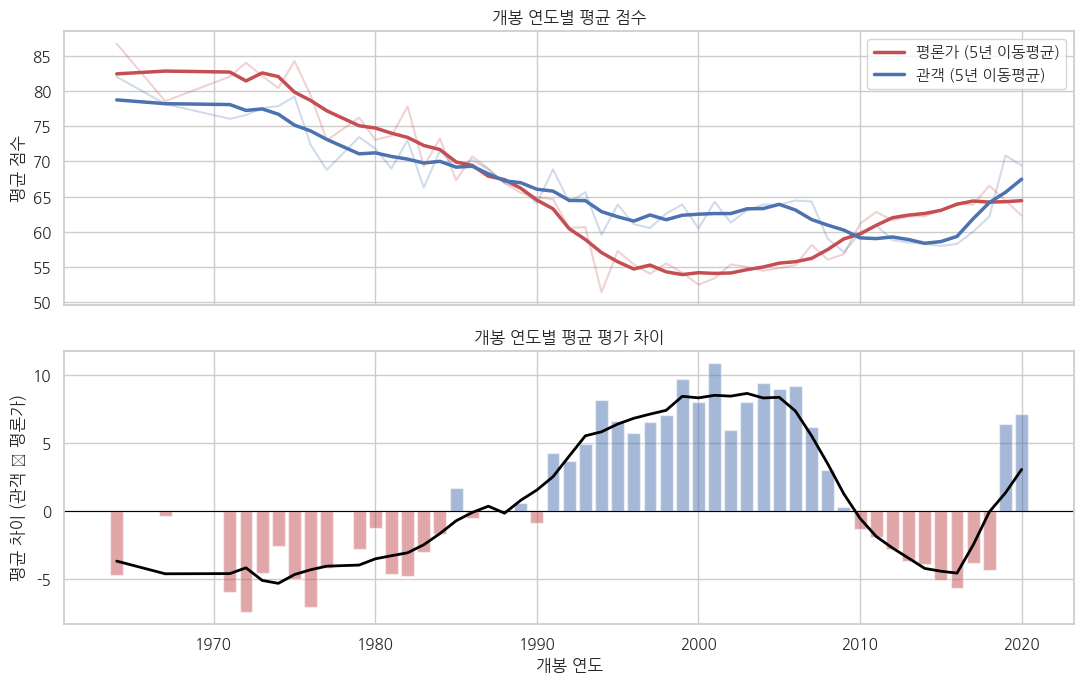

,영화수,평론가,관객,평균차이
decade,,,,
1930년대,77,92.3,80.1,-12.2
1940년대,106,93.7,84.3,-9.5
1950년대,170,90.6,82.9,-7.6
1960년대,223,86.3,81.9,-4.4
1970년대,322,79.3,74.7,-4.5
1980년대,606,70.2,69.1,-1.1
1990년대,1366,56.8,63.0,6.2
2000년대,3109,55.5,62.2,6.7
2010년대,3567,63.0,59.8,-3.2


In [71]:
# ── 연도별 평균 계산 → 30편 이상인 해만 → 5년 이동평균 ──
yearly = df.groupby('year').agg(평론가=('tomatometer_rating', 'mean'), 관객=('audience_rating', 'mean'),
                                차이=('gap', 'mean'), 영화수=('gap', 'size'))
yearly = yearly[yearly['영화수'] >= 30]
yearly.index = yearly.index.astype(int)
smooth = yearly[['평론가', '관객', '차이']].rolling(window=5, center=True, min_periods=3).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(yearly.index, yearly['평론가'], color=CRITIC, alpha=0.25)
axes[0].plot(yearly.index, yearly['관객'], color=AUDIENCE, alpha=0.25)
axes[0].plot(smooth.index, smooth['평론가'], color=CRITIC, lw=2.5, label='평론가 (5년 이동평균)')
axes[0].plot(smooth.index, smooth['관객'], color=AUDIENCE, lw=2.5, label='관객 (5년 이동평균)')
axes[0].set_ylabel('평균 점수'); axes[0].legend(); axes[0].set_title('개봉 연도별 평균 점수')
axes[1].bar(yearly.index, yearly['차이'], color=np.where(yearly['차이'] > 0, AUDIENCE, CRITIC), alpha=0.5)
axes[1].plot(smooth.index, smooth['차이'], color='black', lw=2)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_ylabel('평균 차이 (관객 − 평론가)'); axes[1].set_xlabel('개봉 연도')
axes[1].set_title('개봉 연도별 평균 평가 차이')
save(fig, '15_timeseries'); plt.show()

# ── 시대별 요약 ──
df['decade'] = (df['year'] // 10 * 10).astype(str) + '년대'
decade = df.groupby('decade').agg(영화수=('gap', 'size'), 평론가=('tomatometer_rating', 'mean'),
                                   관객=('audience_rating', 'mean'), 평균차이=('gap', 'mean'))
decade[decade['영화수'] >= 30].round(1)

## 8. 결론

In [72]:
# ── 핵심 결과 자동 요약 ──
g = genre_gap['평균차이']
s = smooth['차이'].dropna()
print(f"1. 분석 영화 {len(df):,}편. 평론가-관객 점수 상관계수는 {r:.2f}로, 대체로 같은 방향이지만 완전히 같지는 않음")
print(f"2. 평가 차이가 20점 이상 벌어지는 영화가 전체의 {(df['gap'].abs() >= 20).mean():.0%}")
print(f"3. 관객이 가장 후한 장르: {g.idxmax()} (평균 {g.max():+.1f}점), 평론가가 가장 후한 장르: {g.idxmin()} (평균 {g.min():+.1f}점)")
print(f"4. 메이저 스튜디오 영화는 평균 {studio_gap.loc['메이저 스튜디오', '평균차이']:+.1f}점, "
      f"예술영화 배급사 영화는 {studio_gap.loc['예술영화 배급사', '평균차이']:+.1f}점으로 평가가 반대로 갈림")
print(f"5. 인기 상위 20% 영화: 평론가 {pop.iloc[-1, 0]:.1f}점 vs 관객 {pop.iloc[-1, 1]:.1f}점 / "
      f"하위 20%: 평론가 {pop.iloc[0, 0]:.1f}점 vs 관객 {pop.iloc[0, 1]:.1f}점")
print(f"6. k-평균 군집 4유형: " + ', '.join(f'{t} {n:,}편' for t, n in df['type'].value_counts().items()))
print(f"7. 튜닝한 랜덤포레스트의 재현율: 교차검증 {gs.best_score_:.3f}, 테스트 {test_recall:.3f} (무작위 0.333)")
print(f"7-1. 테스트 F1 기준 1위 모델: {model_table.index[0]} ({model_table['F1'].iloc[0]:.3f})")
print(f"8. 랜덤포레스트가 꼽은 가장 중요한 변수 3개: {', '.join(imp.index[:3])}")
print(f"9. 평균 평가 차이(5년 이동평균)는 {s.index[0]}년 {s.iloc[0]:+.1f}점 → {s.index[-1]}년 {s.iloc[-1]:+.1f}점으로 변화")

1. 분석 영화 9,615편. 평론가-관객 점수 상관계수는 0.72로, 대체로 같은 방향이지만 완전히 같지는 않음
2. 평가 차이가 20점 이상 벌어지는 영화가 전체의 29%
3. 관객이 가장 후한 장르: 액션·모험 (평균 +5.3점), 평론가가 가장 후한 장르: 다큐멘터리 (평균 -7.2점)
4. 메이저 스튜디오 영화는 평균 +6.0점, 예술영화 배급사 영화는 -7.0점으로 평가가 반대로 갈림
5. 인기 상위 20% 영화: 평론가 57.3점 vs 관객 65.9점 / 하위 20%: 평론가 67.2점 vs 관객 60.4점
6. k-평균 군집 4유형: 명작 (둘 다 좋아함) 3,963편, 혹평작 (둘 다 싫어함) 2,109편, 평론가 픽 (평론가만 좋아함) 2,045편, 관객 픽 (관객만 좋아함) 1,498편
7. 튜닝한 랜덤포레스트의 재현율: 교차검증 0.560, 테스트 0.553 (무작위 0.333)
7-1. 테스트 F1 기준 1위 모델: 랜덤포레스트(튜닝) (0.480)
8. 랜덤포레스트가 꼽은 가장 중요한 변수 3개: 개봉연도, 인기도(관객 평가 수), 등급_NR
9. 평균 평가 차이(5년 이동평균)는 1964년 -3.7점 → 2020년 +3.1점으로 변화
